In [1]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
from src.utils.ds_helper import get_dataset_distribution


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
train_data_dir = os.path.join(dataset_path, "data02", "train")
test_data_dir = os.path.join(dataset_path, "data02", "test")
val_data_dir = os.path.join(dataset_path, "data02", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data02/train
/Users/joshan/Documents/final-year-project/dataset/data02/test
/Users/joshan/Documents/final-year-project/dataset/data02/val


In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 11873 files belonging to 3 classes.


2026-02-22 00:45:21.617490: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-02-22 00:45:21.617519: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-02-22 00:45:21.617538: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-02-22 00:45:21.617581: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-02-22 00:45:21.617613: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Found 1392 files belonging to 3 classes.
Found 694 files belonging to 3 classes.


In [4]:
model = models.Sequential([
    # Preprocessing: Rescale inputs to [0, 1]
    layers.BatchNormalization(),
    
    # First Convolutional Block
    layers.Conv2D(32, (3, 3), activation='sigmoid'),
    layers.MaxPooling2D((2, 2)),
    
    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third Convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), # Helps prevent overfitting
    layers.Dense(3, activation='softmax') # Softmax for multi-class probability
])

In [5]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


2026-02-22 00:46:32.835571: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


372/372 ━━━━━━━━━━━━━━━━━━━━ 63s 154ms/step - accuracy: 0.6457 - loss: 1.9978 - val_accuracy: 0.7983 - val_loss: 1.7993
Epoch 2/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 53s 141ms/step - accuracy: 0.7036 - loss: 5.8053 - val_accuracy: 0.7911 - val_loss: 2.5943
Epoch 3/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 56s 150ms/step - accuracy: 0.7068 - loss: 5.8275 - val_accuracy: 0.7925 - val_loss: 3.0739
Epoch 4/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 54s 144ms/step - accuracy: 0.7225 - loss: 7.5977 - val_accuracy: 0.8069 - val_loss: 5.5266
Epoch 5/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 55s 148ms/step - accuracy: 0.7235 - loss: 14.5954 - val_accuracy: 0.8184 - val_loss: 10.6789
Epoch 6/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 55s 148ms/step - accuracy: 0.7279 - loss: 31.4172 - val_accuracy: 0.7017 - val_loss: 62.9942
Epoch 7/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 55s 148ms/step - accuracy: 0.7318 - loss: 58.8868 - val_accuracy: 0.8242 - val_loss: 32.4684
Epoch 8/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 53s 143ms/step - accuracy: 0.7391 - loss: 78.294

In [6]:
# Save the model
model.save('CX_101.keras')
print("Model saved successfully!")

Model saved successfully!


In [9]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.8527 - loss: 66.5096
Test Loss: 66.50957489013672
Test Accuracy: 85.27%


2026-02-22 01:23:57.379085: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


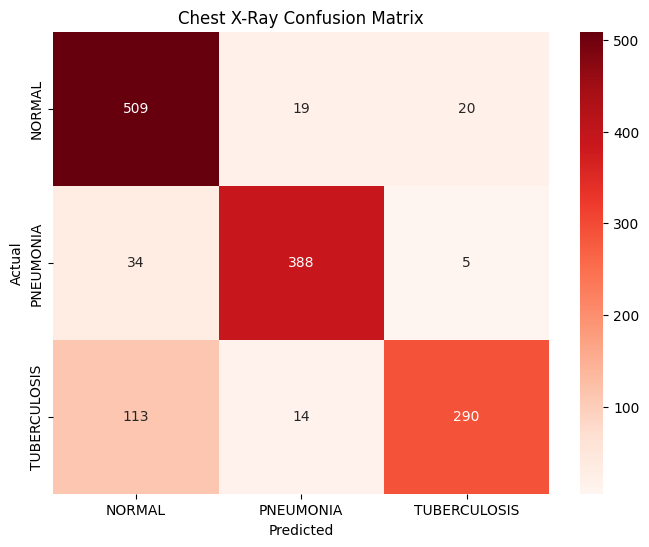

              precision    recall  f1-score   support

      NORMAL       0.78      0.93      0.85       548
   PNEUMONIA       0.92      0.91      0.92       427
TUBERCULOSIS       0.92      0.70      0.79       417

    accuracy                           0.85      1392
   macro avg       0.87      0.84      0.85      1392
weighted avg       0.86      0.85      0.85      1392



In [10]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Chest X-Ray Confusion Matrix')
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))